# 3.0 Transformación JobPath (CRISP-DM Fase 3: Preparación de Datos)

**Fase CRISP-DM:** 3. *Data Preparation* — bloque de selección, construcción, integración y formateo de variables (*Select / Construct / Integrate / Format Data*).
**Enlace con el negocio (Charter `1.0_comprension_negocio.md`):** *"Descubrir y caracterizar patrones de transición ocupacional en trayectorias post-formación, mediante técnicas de minería sobre secuencias (no supervisada)"*.
**Entradas que recibe (`data/03_processed/`):**
- **Versión A (`con_outliers`):** `empleos_unificado_limpio.csv` (`1,871,014` filas × `23` columnas, `355,308` personas).
- **Versión B (`sin_outliers`):** `empleos_limpio_con_competencias_sin_outliers.csv` (`1,871,014` filas × `23` columnas, `355,308` personas, winsorizada por IQR en `2.0`).

**Salidas que regenera (`data/04_transformed/`):**
- `con_outliers/train/{X_train.csv, y_train.csv}` y `con_outliers/test/{X_test.csv, y_test.csv}`
- `sin_outliers/train/{X_train.csv, y_train.csv}` y `sin_outliers/test/{X_test.csv, y_test.csv}`
- `transformers/con_outliers/transformers.joblib` y `transformers/sin_outliers/transformers.joblib`

In [1]:
# Cell 1: All library and module imports, relative paths, and fixed random seed
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Preproccesing.config import DEFAULT_CONFIG
from scripts.ScriptsCsv.Preproccesing.funnel import RowCountFunnel
from scripts.ScriptsCsv.Transformacion.config import (
    VERSION_CON, VERSION_SIN, processed_path
)
from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.comparison import (
    material_difference_summary, pair_distance_analysis
)
from scripts.ScriptsCsv.Transformacion.date_features import (
    add_date_ordinals, add_job_order, add_start_year
)
from scripts.ScriptsCsv.Transformacion.decision_log import DecisionLog
from scripts.ScriptsCsv.Transformacion.discretization import (
    fit_discretizers, report_edges, transform_discretizers
)
from scripts.ScriptsCsv.Transformacion.encoding import (
    derive_skill_presence, fit_onehot, ordinal_from_mapping,
    reduce_high_cardinality, transform_onehot
)
from scripts.ScriptsCsv.Transformacion.export import (
    ensure_dir, save_frame, save_transformers
)
from scripts.ScriptsCsv.Transformacion.scaler_recommendation import recommend_scalers
from scripts.ScriptsCsv.Transformacion.scaling import (
    fit_transform_full, scaled_column_name
)
from scripts.ScriptsCsv.Transformacion.split import (
    fit_transform_train_test, group_train_test_split
)
from scripts.ScriptsCsv.Transformacion.validation import (
    assert_validation, validate_transformed
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

TRANSFORMED_ROOT = ROOT / "data" / "04_transformed"

print("Raíz:", ROOT)
print("Transformed root:", TRANSFORMED_ROOT)

Raíz: c:\Users\User\Documents\JobPath\MineriaProtect
Transformed root: c:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed


In [2]:
# Cell 2: Business and feature transformation configuration
TARGET_MODE = "reincide"          # Auxiliary evaluation target: occupation repetition (veces_ese_oficio > 1)
TEST_SIZE = 0.20
RANDOM_SEED = 42
HIGH_CARD_STRATEGY = "all"        # all | top_n | frequency_threshold | prefix

# Selected continuous/count columns to scale (identifiers, codes, and dummies are never scaled)
SELECTED_NUMERIC = [
    "start_ord", "end_ord", "dur_q",
    "n_skills_essential", "n_skills_competence",
    "n_skills_knowledge", "n_skills_sin_tipo",
    "veces_ese_oficio", "start_year", "job_order",
]

# Scaling plan justified by skewness and Tukey outlier rate in recommend_scalers
SCALING_PLAN = {
    "start_ord": "robust",
    "end_ord": "robust",
    "dur_q": "robust",
    "n_skills_essential": "robust",
    "n_skills_competence": "robust",
    "n_skills_knowledge": "robust",
    "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust",
    "start_year": "robust",
    "job_order": "robust",
    "univ_ord": "minmax",
}

# Nominal columns for OneHotEncoder (drop='first' avoids exact collinearity)
ONEHOT_COLUMNS = ["emparejado", "occupation_code"]
ONEHOT_DROP_FIRST = True

# Genuine ordinal hierarchy for education level
UNIV_ORDER = {
    "No reportado": 0,
    "Secondary school": 1,
    "Bachelor": 2,
    "Master": 3,
    "PhD": 4,
}

# Quantile discretization for business interpretability
DISCRETIZATION_COLUMNS = ["dur_q", "n_skills_essential", "veces_ese_oficio"]
DISCRETIZATION_SPEC = {
    "columns": DISCRETIZATION_COLUMNS,
    "n_bins": 4,
    "strategy": "quantile",
    "labels": {
        "dur_q": ["trayectoria corta", "trayectoria media", "trayectoria larga", "trayectoria muy larga"],
        "n_skills_essential": ["oficio de baja carga", "oficio de carga media", "oficio de alta carga", "oficio de carga muy alta"],
        "veces_ese_oficio": ["single", "reincidencia baja", "reincidencia media", "reincidencia alta"],
    },
}

# Unscaled binary and presence flags
BINARY_COLUMNS = ["es_vigente"]
PRESENCE_COLUMNS = ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"]
EXPORT_DECISION_LOG = False

## 1. *Select Data*: Perfil completo de ambas versiones (`con_outliers` y `sin_outliers`)

Se leen ambas versiones en memoria RAM sin alterar los archivos CSV de `data/03_processed/`. A continuación se derivan las variables temporales (`start_ord`, `end_ord`, `dur_q`, `start_year`), el orden cronológico del empleo dentro de la trayectoria de la persona (`job_order`), la codificación ordinal del nivel educativo (`univ_ord`), las banderas binarias de presencia de competencias (`tiene_skills`, `tiene_knowledge`, `tiene_sin_tipo`) y la variable objetivo auxiliar `reincide` (`veces_ese_oficio > 1`).

In [3]:
# Load each version into RAM and derive temporal, ordinal, and presence features
def read_version(version: str) -> pd.DataFrame:
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    # Fill occupation_code for rescued rows using matched_code when available
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")

    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    skill_cols = ["skills", "knowledge", "sin_tipo"]
    flag_cols = ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"]
    df = derive_skill_presence(df, skill_cols, flag_cols)
    if "university_level" in df.columns:
        df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    else:
        df["univ_ord"] = 0
    for col in ["es_unknown_ocupacion", "es_rescatado", "es_vigente"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.lower().map({"true": 1, "false": 0}).fillna(0).astype("int8")
    df["reincide"] = (df["veces_ese_oficio"].fillna(0) > 1).astype("int8")
    if HIGH_CARD_STRATEGY != "all":
        df["occupation_code"] = reduce_high_cardinality(df["occupation_code"], HIGH_CARD_STRATEGY)
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
print("Versiones cargadas:", df_con.shape, df_sin.shape)

Versiones cargadas: (1871014, 33) (1871014, 33)


In [4]:
# Build column profile table for both versions (33 columns each)
profiles = pd.concat(
    [profile_columns(df_con, VERSION_CON), profile_columns(df_sin, VERSION_SIN)],
    ignore_index=True,
)
display(profiles[["version", "column", "dtype", "n_null", "cardinality", "zero_pct", "skewness", "kurtosis", "type_class", "relevant", "reason"]])
print("\nColumnas relevantes versión con outliers:", int(profiles.loc[(profiles.version == VERSION_CON) & profiles.relevant, "column"].nunique()))

,version,column,dtype,n_null,cardinality,zero_pct,skewness,kurtosis,type_class,relevant,reason
0,con_outliers,resume_id,str,0,355308,0.000534,-0.000321,-1.201047,identifier,False,Identificador de persona: indispensable para e...
1,con_outliers,start_date,str,0,226,NaN,NaN,NaN,date,True,Fecha de inicio del empleo: se deriva a ordina...
2,con_outliers,end_date,str,0,226,NaN,NaN,NaN,date,True,Fecha de fin o censura Present: define duració...
3,con_outliers,university_level,str,0,5,NaN,NaN,NaN,ordinal,True,"Nivel educativo: jerarquía real, sirve como or..."
4,con_outliers,matched_code,str,0,2991,0.000000,0.358440,-1.092018,identifier,False,Código JobHop: se interpreta mediante ESCO; oc...
...,...,...,...,...,...,...,...,...,...,...,...
61,sin_outliers,tiene_skills,uint8,0,2,7.070444,-3.349550,9.219495,binary,True,Bandera binaria 0/1 de presencia de lista de s...
62,sin_outliers,tiene_knowledge,uint8,0,2,16.547017,-1.800464,1.241671,binary,True,Bandera binaria 0/1 de presencia de lista de c...
63,sin_outliers,tiene_sin_tipo,uint8,0,2,99.165693,10.810576,114.868685,binary,True,Bandera binaria 0/1 de presencia de competenci...
64,sin_outliers,univ_ord,int64,0,5,11.523163,0.124589,-0.607414,ordinal,True,Nivel educativo codificado ordinalmente (0..4)...



Columnas relevantes versión con outliers: 27


### Decisión por columna (*Select Data*)

`COLUMN_DECISIONS` documenta explícitamente qué variables se conservan, escalan, codifican, transforman o descartan antes de ensamblar `X`.

> **Nota sobre `veces_ese_oficio` y auditoría de fuga (*leakage*):** La variable `reincide` se define exactamente como `veces_ese_oficio > 1`. En esta fase de preparación se conservan `veces_ese_oficio_rob` y `veces_ese_oficio_bin` dentro de la matriz exportada `X` para que el cuaderno `5.0_EDA_jobpath.ipynb` (Sección 8, Figura `G30`) ejecute la auditoría empírica de fuga de datos y demuestre su separación determinista con `reincide`, debiendo excluirse al entrenar cualquier clasificador supervisado.

In [5]:
# Document explicit inclusion/exclusion decision for every column
COLUMN_DECISIONS = {
    "resume_id": ("drop", "Identificador de persona; se usa exclusivamente para agrupar el split train/test y no como feature."),
    "start_date": ("drop", "Texto trimestral; reemplazado por start_ord y start_year."),
    "end_date": ("drop", "Texto trimestral; reemplazado por end_ord, dur_q y es_vigente."),
    "university_level": ("transform", "Se mapea ordinalmente a univ_ord (0..4 según jerarquía académica real)."),
    "matched_code": ("drop", "Código intermedio de emparejamiento; occupation_code conserva la hoja ESCO."),
    "emparejado": ("encode", "Nominal: se codifica con OneHotEncoder(drop='first')."),
    "occupation_code": ("encode", "Nominal de alta cardinalidad (2,973 oficios ESCO): OneHotEncoder(drop='first', dtype=uint8)."),
    "occupation_label": ("drop", "Etiqueta textual redundante con occupation_code."),
    "isco_group": ("drop", "Grupo ISCO de 4 dígitos; reservado para interpretación agregada en EDA."),
    "isco_group_label": ("drop", "Etiqueta textual redundante con isco_group."),
    "isco_level": ("drop", "Constante (4.0) en toda la fuente; varianza e IQR iguales a 0."),
    "n_skills_essential": ("scale", "Conteo numérico ESCO; se escala con RobustScaler y se discretiza en cuantiles."),
    "n_skills_competence": ("scale", "Conteo numérico ESCO; se escala con RobustScaler."),
    "n_skills_knowledge": ("scale", "Conteo numérico ESCO; se escala con RobustScaler."),
    "n_skills_sin_tipo": ("scale", "Conteo numérico ESCO; se escala con RobustScaler."),
    "veces_ese_oficio": ("scale/audit", "Se escala (veces_ese_oficio_rob) y discretiza (_bin); auditado por colinealidad/fuga con reincide en 5.0_EDA."),
    "saber_skills": ("drop", "Constante ('ok') dentro del universo modelable con competencias."),
    "es_unknown_ocupacion": ("drop", "Constante (0) dentro del universo con oficio clasificado."),
    "es_rescatado": ("drop", "Constante (0) dentro del universo con oficio clasificado."),
    "es_vigente": ("keep", "Bandera binaria 0/1 de empleo vigente (censura derecha); entra sin escalar."),
    "skills": ("transform", "Texto crudo ESCO; resumido en n_skills_* y bandera tiene_skills."),
    "knowledge": ("transform", "Texto crudo ESCO; resumido en n_skills_knowledge y bandera tiene_knowledge."),
    "sin_tipo": ("transform", "Texto crudo ESCO; resumido en n_skills_sin_tipo y bandera tiene_sin_tipo."),
    "start_ord": ("scale", "Ordinal trimestral de inicio; se escala con RobustScaler."),
    "end_ord": ("scale", "Ordinal trimestral de término; se escala con RobustScaler."),
    "dur_q": ("scale", "Duración trimestral del empleo; se escala con RobustScaler y se discretiza."),
    "start_year": ("scale", "Año de inicio del empleo; se escala con RobustScaler."),
    "job_order": ("scale", "Orden cronológico del empleo en la trayectoria; se escala con RobustScaler."),
    "univ_ord": ("scale", "Ordinal educativo en rango acotado [0, 4]; se escala con MinMaxScaler."),
    "reincide": ("target", "Etiqueta auxiliar binaria (veces_ese_oficio > 1); se exporta en y_train/y_test fuera de X."),
}
decision_df = pd.DataFrame(
    [{"column": k, "decision": v[0], "justification": v[1]} for k, v in COLUMN_DECISIONS.items()]
)
display(decision_df)

,column,decision,justification
0,resume_id,drop,Identificador de persona; se usa exclusivament...
1,start_date,drop,Texto trimestral; reemplazado por start_ord y ...
2,end_date,drop,"Texto trimestral; reemplazado por end_ord, dur..."
3,university_level,transform,Se mapea ordinalmente a univ_ord (0..4 según j...
4,matched_code,drop,Código intermedio de emparejamiento; occupatio...
5,emparejado,encode,Nominal: se codifica con OneHotEncoder(drop='f...
6,occupation_code,encode,"Nominal de alta cardinalidad (2,973 oficios ES..."
7,occupation_label,drop,Etiqueta textual redundante con occupation_code.
8,isco_group,drop,Grupo ISCO de 4 dígitos; reservado para interp...
9,isco_group_label,drop,Etiqueta textual redundante con isco_group.


## 2. Variable Objetivo Auxiliar `reincide` (`Y`)

El proyecto es de naturaleza no supervisada (minería de secuencias y transiciones ocupacionales), pero define la etiqueta binaria auxiliar `reincide = (veces_ese_oficio > 1)` para evaluar qué variables del perfil laboral distinguen la repetición de un oficio frente a la exploración de oficios nuevos. En el dataset completo (`1,871,014` filas) la prevalencia bruta es `0.2788` (`27.88%`), y dentro del universo clasificado con competencias (`1,738,738` filas) es **`0.3000` (`30.00%`)**, mostrando un balance estable `70% / 30%`.

In [6]:
# Check target prevalence and unique person counts before filtering unmapped occupations
print("Prevalencia bruta reincide (con):", round(float(df_con.reincide.mean()), 4))
print("Prevalencia bruta reincide (sin):", round(float(df_sin.reincide.mean()), 4))
print("Personas totales (con):", df_con.resume_id.nunique(), "| (sin):", df_sin.resume_id.nunique())

Prevalencia bruta reincide (con): 0.2788
Prevalencia bruta reincide (sin): 0.2788
Personas totales (con): 355308 | (sin): 355308


## 3. Universo de Trabajo y Embudo de Filas/Personas: Filtrado de Oficios Clasificados

Las `132,276` filas (`7.07%`) sin competencias corresponden a empleos cuyo texto libre no pudo asociarse a una ocupación hoja de ESCO (`saber_skills == 'no_clasificado'`: `128,981` `unknown` + `3,295` `rescatado` sin hoja). En la matriz `X` **no se inventa un 0** para no confundir "oficio desconocido" con "oficio que exige cero competencias".

El **Embudo de Filas y Personas (*Row-Count Funnel*)** registra este filtro y dispara la alerta programada (`> 5.0%` en filas: `7.07%` de filas descartadas, pero solo `0.90%` de personas descartadas), dejando **`1,738,738` experiencias laborales y `352,093` personas** con cobertura completa.

In [7]:
# Filter to classified occupations (n_skills_essential.notna()) and track with RowCountFunnel
def universe(df: pd.DataFrame, version_label: str):
    funnel = RowCountFunnel(person_col="resume_id", alert_threshold_pct=5.0)
    funnel.record_step(
        f"1. Entrada {version_label} (03_processed)",
        df,
        note="Dataset unificado limpio completo",
    )
    before_rows = len(df)
    before_persons = df.resume_id.nunique()
    work = df[df.n_skills_essential.notna()].copy().reset_index(drop=True)
    funnel.record_step(
        f"2. Filtro universo con oficio ESCO ({version_label})",
        work,
        note="Exclusión deliberada de saber_skills=='no_clasificado' (7.07% filas, 0.90% personas)",
    )
    informe = {
        "before_rows": before_rows,
        "before_persons": before_persons,
        "after_rows": len(work),
        "after_persons": work.resume_id.nunique(),
        "rows_lost": before_rows - len(work),
        "persons_lost": before_persons - work.resume_id.nunique(),
        "row_loss_pct": round((before_rows - len(work)) / before_rows * 100, 2),
        "person_loss_pct": round((before_persons - work.resume_id.nunique()) / before_persons * 100, 2),
    }
    return work, informe, funnel.to_dataframe()

work_con, informe_con, funnel_con_df = universe(df_con, "Versión A (con outliers)")
work_sin, informe_sin, funnel_sin_df = universe(df_sin, "Versión B (sin outliers)")
print("Informe con outliers:", informe_con)
print("Informe sin outliers:", informe_sin)
display(funnel_con_df)

[ALERTA EMBUDO > 5.0%] Etapa '2. Filtro universo con oficio ESCO (Versión A (con outliers))': filas perdidas = 132276 (7.07%), personas perdidas = 3215 (0.90%). Exclusión deliberada de saber_skills=='no_clasificado' (7.07% filas, 0.90% personas)


[ALERTA EMBUDO > 5.0%] Etapa '2. Filtro universo con oficio ESCO (Versión B (sin outliers))': filas perdidas = 132276 (7.07%), personas perdidas = 3215 (0.90%). Exclusión deliberada de saber_skills=='no_clasificado' (7.07% filas, 0.90% personas)


Informe con outliers: {'before_rows': 1871014, 'before_persons': 355308, 'after_rows': 1738738, 'after_persons': 352093, 'rows_lost': 132276, 'persons_lost': 3215, 'row_loss_pct': 7.07, 'person_loss_pct': 0.9}
Informe sin outliers: {'before_rows': 1871014, 'before_persons': 355308, 'after_rows': 1738738, 'after_persons': 352093, 'rows_lost': 132276, 'persons_lost': 3215, 'row_loss_pct': 7.07, 'person_loss_pct': 0.9}


,etapa,filas_antes,filas_despues,filas_perdidas,pct_filas_perdidas,personas_antes,personas_despues,personas_perdidas,pct_personas_perdidas,alerta_umbral_5pct,nota
0,1. Entrada Versión A (con outliers) (03_proces...,1871014,1871014,0,0.0000,355308,355308,0,0.0000,OK (<=5%),Dataset unificado limpio completo
1,2. Filtro universo con oficio ESCO (Versión A ...,1871014,1738738,132276,7.0697,355308,352093,3215,0.9048,ALERTA (>5%),Exclusión deliberada de saber_skills=='no_clas...


## 4. Recomendación de Escaladores con Evidencia Estadística

Regla de decisión aplicada por `recommend_scalers`:
- **`StandardScaler`**: variables simétricas cercanas a distribución normal sin valores extremos.
- **`MinMaxScaler`**: variables ordinales de rango acotado sin outliers graves (`univ_ord` en `[0, 4]`).
- **`RobustScaler`**: variables numéricas con asimetría marcada (`|skewness| > 1`) o presencia de valores más allá de las vallas de Tukey (`pct_outside_tukey > 0.5%`), escalando con mediana e `IQR` para evitar que las colas distorsionen las distancias.

In [8]:
recommendation = recommend_scalers(work_con, [c for c in SELECTED_NUMERIC if c in work_con.columns and c != "univ_ord"])
display(recommendation)
print("univ_ord -> MinMax por regla de rango acotado.")


,column,skewness,kurtosis,pct_outside_tukey,top_value_frequency_pct,recommended_scaler,evidence
0,start_ord,-1.470104,2.230549,5.569039,4.934383,RobustScaler,Colas o valores extremos reales; la mediana y ...
1,end_ord,-1.040120,2.261173,4.684720,5.461777,RobustScaler,Colas o valores extremos reales; la mediana y ...
2,dur_q,3.252944,13.975853,11.551539,29.499672,RobustScaler,Colas o valores extremos reales; la mediana y ...
3,n_skills_essential,2.196893,6.541646,5.034514,11.192773,RobustScaler,Colas o valores extremos reales; la mediana y ...
4,n_skills_competence,1.902015,4.554140,4.936684,7.694834,RobustScaler,Colas o valores extremos reales; la mediana y ...
5,n_skills_knowledge,3.801095,23.548221,2.011229,17.408143,RobustScaler,Colas o valores extremos reales; la mediana y ...
6,n_skills_sin_tipo,11.711616,151.995386,0.897778,99.102222,RobustScaler,Colas o valores extremos reales; la mediana y ...
7,veces_ese_oficio,3.104542,14.092653,5.688379,69.995710,RobustScaler,Colas o valores extremos reales; la mediana y ...
8,start_year,-1.480130,2.265555,5.621894,7.682469,RobustScaler,Colas o valores extremos reales; la mediana y ...
9,job_order,1.272352,1.881832,4.789796,18.925738,RobustScaler,Colas o valores extremos reales; la mediana y ...


univ_ord -> MinMax por regla de rango acotado.


## 5. Encoding, derivaciones y Scaling

Se ajustan escaladores, one-hot y discretizadores de forma reproducible. El flujo real por persona se realiza en la seccion de split.


In [9]:
# Verify scaling plan columns and compute diagnostic full-sample scaled matrices
scaling_plan = dict(SCALING_PLAN)

for c in scaling_plan:
    if c not in work_con.columns:
        raise KeyError(f"Columna inexistente en work_con: {c}")

fitted_con, scaled_con = fit_transform_full(work_con[sorted(set(scaling_plan))], scaling_plan)
fitted_sin, scaled_sin = fit_transform_full(work_sin[sorted(set(scaling_plan))], scaling_plan)

print("Formas escaladas (universo clasificado):", scaled_con.shape, scaled_sin.shape)

Formas escaladas (universo clasificado): (1738738, 11) (1738738, 11)


## 6. Discretización por Cuantiles con `KBinsDiscretizer`

Se discretizan `dur_q`, `n_skills_essential` y `veces_ese_oficio` mediante `KBinsDiscretizer(n_bins=4, strategy='quantile')`. Debido a la concentración de empates en valores enteros bajos (`dur_q == 2` y `veces_ese_oficio == 1`), `KBinsDiscretizer` fusiona automáticamente los bordes duplicados produciendo **3 segmentos efectivos en `dur_q`** (`[2, 5)`, `[5, 13)`, `[13, 225]`), **4 segmentos en `n_skills_essential`** (`[5, 15)`, `[15, 20)`, `[20, 28)`, `[28, 99]`) y **2 segmentos en `veces_ese_oficio`** (`[1, 2)` experiencia única vs `[2, 19]` reincidente).

In [10]:
discretizers_con = fit_discretizers(work_con, DISCRETIZATION_COLUMNS, n_bins=DISCRETIZATION_SPEC["n_bins"], strategy=DISCRETIZATION_SPEC["strategy"])
discretization_report = report_edges(discretizers_con, work_con, DISCRETIZATION_SPEC["labels"])
display(discretization_report)
print("\nBines (con) =", {k: int(v) for k, v in zip(DISCRETIZATION_COLUMNS, [DISCRETIZATION_SPEC['n_bins']] * len(DISCRETIZATION_COLUMNS))})


,column,bin,label,left_edge,right_edge,count
0,dur_q,0,trayectoria corta,2.0,5.0,590675
1,dur_q,1,trayectoria media,5.0,13.0,646825
2,dur_q,2,trayectoria larga,13.0,225.0,501238
3,n_skills_essential,0,oficio de baja carga,5.0,15.0,409849
4,n_skills_essential,1,oficio de carga media,15.0,20.0,316479
5,n_skills_essential,2,oficio de alta carga,20.0,28.0,570459
6,n_skills_essential,3,oficio de carga muy alta,28.0,99.0,441951
7,veces_ese_oficio,0,single,1.0,2.0,1217042
8,veces_ese_oficio,1,reincidencia baja,2.0,19.0,521696



Bines (con) = {'dur_q': 4, 'n_skills_essential': 4, 'veces_ese_oficio': 4}


## 7. Diagnóstico PCA (Delegado a los Cuadernos Satélite `4.0` y `4.1`)

El ajuste y análisis de Componentes Principales (PCA) sobre las matrices `X_train` generadas aquí se realiza en los cuadernos dedicados `4.0_PCA.ipynb` (muestra de `10,000` filas) y `4.1_PCA_completo.ipynb` (muestra de `50,000` filas). De este modo, `3.0` conserva una responsabilidad única (*Select / Construct / Integrate / Format Data*) y exporta los artefactos que alimentan el diagnóstico espectral.

## 8. Comparación: Versión A (`con_outliers`) vs Versión B (`sin_outliers`) y Efecto del Escalado

Se cuantifican las filas y columnas con diferencias materiales entre las dos versiones (`193,596` filas con al menos uno de los 4 conteos acotados por winsorización IQR, equivalentes al `10.35%` del total de `1,871,014` filas) y se evalúa cómo el escalado robusto comprime las distancias euclídeas entre pares aleatorios de experiencias manteniendo una alta correlación estructural con las distancias originales.

,metric,A con outliers,B sin outliers
0,rows,1871014,1871014
1,columns,33,33
2,materially_different_rows,193596,193596
3,columns_with_differences,4,4


,pair_index,distance_raw,distance_scaled
count,500.000000,500.000000,500.000000
mean,249.500000,62.646957,3.934375
std,144.481833,42.429368,2.325831
min,0.000000,4.358899,0.724131
25%,124.750000,28.783482,2.352784
50%,249.500000,50.034988,3.356619
75%,374.250000,87.346977,4.934480
max,499.000000,217.680959,16.684065


Correlacion distancia raw vs scaled: 0.7628


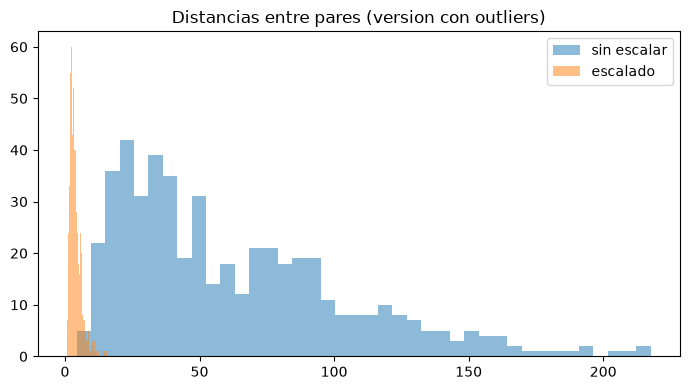

In [11]:
raw_mix = material_difference_summary(df_con, df_sin, "A con outliers", "B sin outliers")
display(raw_mix)

# Parejas de distancia (muestra): sin escalar vs escalado para la version con outliers
numeric_raw = work_con[SELECTED_NUMERIC].reset_index(drop=True)
numeric_scaled = scaled_con.reset_index(drop=True)
distances = pair_distance_analysis(numeric_raw, numeric_scaled, n_rows=400, n_pairs=500, random_state=RANDOM_SEED)
display(distances.describe())
print("Correlacion distancia raw vs scaled:", round(distances.distance_raw.corr(distances.distance_scaled), 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(distances.distance_raw, bins=40, alpha=0.5, label="sin escalar")
ax.hist(distances.distance_scaled, bins=40, alpha=0.5, label="escalado")
ax.set_title("Distancias entre pares (version con outliers)")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Train/test split por persona (`resume_id`)

Regla de oro: split por persona, nunca por fila. Los scalers/encoders/discretizadores se ajustan solo en train y despues transforman test.


In [12]:
# Split universe by person (resume_id) with fixed seed=42 (80% train / 20% test)
train_con, test_con = group_train_test_split(work_con, group_col="resume_id", test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_sin, test_sin = group_train_test_split(work_sin, group_col="resume_id", test_size=TEST_SIZE, random_state=RANDOM_SEED)

print("A con outliers: train/test rows", train_con.shape, test_con.shape)
print("B sin outliers: train/test rows", train_sin.shape, test_sin.shape)
print("Personas en train / test:", train_con.resume_id.nunique(), test_con.resume_id.nunique())

A con outliers: train/test rows (1391018, 33) (347720, 33)
B sin outliers: train/test rows (1391018, 33) (347720, 33)
Personas en train / test: 281674 70419


In [13]:
DISC_LABELS = DISCRETIZATION_SPEC["labels"]

X_train_con, X_test_con, artifacts_con = fit_transform_train_test(
    train_df=train_con,
    test_df=test_con,
    scaling_plan=scaling_plan,
    onehot_cols=ONEHOT_COLUMNS,
    discretization_spec=DISCRETIZATION_SPEC,
    binary_cols=BINARY_COLUMNS,
    presence_cols=PRESENCE_COLUMNS,
    drop_first=ONEHOT_DROP_FIRST,
)

X_train_sin, X_test_sin, artifacts_sin = fit_transform_train_test(
    train_df=train_sin,
    test_df=test_sin,
    scaling_plan=scaling_plan,
    onehot_cols=ONEHOT_COLUMNS,
    discretization_spec=DISCRETIZATION_SPEC,
    binary_cols=BINARY_COLUMNS,
    presence_cols=PRESENCE_COLUMNS,
    drop_first=ONEHOT_DROP_FIRST,
)

print("X_train_con:", X_train_con.shape, "X_test_con:", X_test_con.shape)
print("X_train_sin:", X_train_sin.shape, "X_test_sin:", X_test_sin.shape)

y_train_con = train_con["reincide"] if TARGET_MODE == "reincide" else None
y_test_con = test_con["reincide"] if TARGET_MODE == "reincide" else None
y_train_sin = train_sin["reincide"] if TARGET_MODE == "reincide" else None
y_test_sin = test_sin["reincide"] if TARGET_MODE == "reincide" else None


X_train_con: (1391018, 2985) X_test_con: (347720, 2985)
X_train_sin: (1391018, 2985) X_test_sin: (347720, 2985)


## 10. Validacion final

Se comprueban nulos, infinitos, formas, personas compartidas y estadisticos de columnas escaladas. Las dummies deben quedar en 0/1 y Y no debe estar dentro de X.


In [14]:
# Validate transformed matrices (shapes, 0 nulls, 0 infinities, 0 shared persons, scaled stats)
report_con = validate_transformed(
    X_train=X_train_con,
    X_test=X_test_con,
    y_train=y_train_con,
    y_test=y_test_con,
    train_persons=set(train_con.resume_id.astype(str)),
    test_persons=set(test_con.resume_id.astype(str)),
    scaled_columns=[scaled_column_name(c, scaling_plan[c]) for c in scaling_plan if scaled_column_name(c, scaling_plan[c]) in X_train_con.columns],
)
assert_validation(report_con)
print("Reporte A (con outliers):", {k: v for k, v in report_con.items() if k != "scaled_columns"})
print("Estadísticos columnas escaladas A (train):")
display(pd.DataFrame(report_con["scaled_columns"]).T)

report_sin = validate_transformed(
    X_train=X_train_sin,
    X_test=X_test_sin,
    y_train=y_train_sin,
    y_test=y_test_sin,
    train_persons=set(train_sin.resume_id.astype(str)),
    test_persons=set(test_sin.resume_id.astype(str)),
    scaled_columns=[scaled_column_name(c, scaling_plan[c]) for c in scaling_plan if scaled_column_name(c, scaling_plan[c]) in X_train_sin.columns],
)
assert_validation(report_sin)
print("\nReporte B (sin outliers):", {k: v for k, v in report_sin.items() if k != "scaled_columns"})
print("Estadísticos columnas escaladas B (train):")
display(pd.DataFrame(report_sin["scaled_columns"]).T)

Reporte A (con outliers): {'X_train_shape': (1391018, 2985), 'X_test_shape': (347720, 2985), 'train_nulls': 0, 'test_nulls': 0, 'train_infinities': 0, 'test_infinities': 0, 'shared_persons': 0, 'columns_identical': True, 'binary_like_columns_checked': 2972, 'target_in_features': False, 'y_train_prevalence': 0.3001190495018756, 'y_test_prevalence': 0.2997382951800299}
Estadísticos columnas escaladas A (train):


,train_mean,train_std,train_median,train_min,train_max
start_ord_rob,-0.2409,0.9002,0.00,-6.1667,1.5000
end_ord_rob,-0.1819,0.9667,0.00,-5.8438,1.6562
dur_q_rob,0.7138,1.7218,0.00,-0.2727,24.7273
n_skills_essential_rob,0.2592,1.0331,0.00,-1.3077,6.0769
n_skills_competence_rob,0.1231,1.0306,0.00,-1.6364,4.6364
n_skills_knowledge_rob,0.2012,0.8658,0.00,-0.6000,8.4000
n_skills_sin_tipo_rob,0.0096,0.1041,0.00,0.0000,2.0000
veces_ese_oficio_rob,0.5353,1.0759,0.00,0.0000,18.0000
start_year_rob,-0.2021,0.8946,0.00,-6.1111,1.5556
job_order_rob,0.3271,0.9239,0.00,-0.6667,5.6667



Reporte B (sin outliers): {'X_train_shape': (1391018, 2985), 'X_test_shape': (347720, 2985), 'train_nulls': 0, 'test_nulls': 0, 'train_infinities': 0, 'test_infinities': 0, 'shared_persons': 0, 'columns_identical': True, 'binary_like_columns_checked': 2972, 'target_in_features': False, 'y_train_prevalence': 0.3001190495018756, 'y_test_prevalence': 0.2997382951800299}
Estadísticos columnas escaladas B (train):


,train_mean,train_std,train_median,train_min,train_max
start_ord_rob,-0.2409,0.9002,0.00,-6.1667,1.5000
end_ord_rob,-0.1819,0.9667,0.00,-5.8438,1.6562
dur_q_rob,0.7138,1.7218,0.00,-0.2727,24.7273
n_skills_essential_rob,0.1782,0.7699,0.00,-1.3077,2.1154
n_skills_competence_rob,0.0454,0.7933,0.00,-1.6364,1.9545
n_skills_knowledge_rob,0.1556,0.6326,0.00,-0.6000,2.1000
n_skills_sin_tipo_rob,0.0096,0.1041,0.00,0.0000,2.0000
veces_ese_oficio_rob,0.4531,0.7723,0.00,0.0000,2.5000
start_year_rob,-0.2021,0.8946,0.00,-6.1111,1.5556
job_order_rob,0.3271,0.9239,0.00,-0.6667,5.6667


## 11. Decision log (CRISP-DM)

La bitacora deja explicita columna, decision, metodo y justificacion para cada transformacion relevante.


In [15]:
# Build CRISP-DM Phase 3 decision log in RAM
log = DecisionLog()
for col in SELECTED_NUMERIC:
    log.add(col, "escalar", SCALING_PLAN.get(col, "robust"), "Numérico con asimetría y colas reales; se escala con RobustScaler ajustado solo en train.", "Construct data")
log.add("univ_ord", "escalar", "minmax", "Jerarquía ordinal acotada [0..4] escalada a [0..1] con MinMaxScaler en train.", "Construct data")
for col in ONEHOT_COLUMNS:
    log.add(col, "one-hot", "OneHotEncoder(drop='first', dtype=uint8)", "Variable nominal codificada en binario compacto sin orden artificial.", "Construct data")
log.add("university_level", "ordinal mapping", "map manual 0..4", "Jerarquía genuina de nivel educativo.", "Construct data")
for col in DISCRETIZATION_COLUMNS:
    log.add(col, "discretizar", "KBinsDiscretizer (quantile, n_bins=4)", "Segmentación por cuantiles interpretable para el negocio.", "Construct data")
log.add("resume_id", "split", "GroupShuffleSplit(test_size=0.20, seed=42)", "Partición agrupada por persona (281,674 train / 70,419 test; 0 compartidas).", "Format data")
frame_log = log.to_frame()
display(frame_log)
if EXPORT_DECISION_LOG:
    ensure_dir(TRANSFORMED_ROOT / "logs")
    frame_log.to_csv(TRANSFORMED_ROOT / "logs" / "decision_log.csv", index=False, encoding="utf-8")
    print("Decision log exportado.")
else:
    print("Decision log mantenido en RAM (EXPORT_DECISION_LOG=False).")

,column,decision,method,justification,phase_task
0,start_ord,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
1,end_ord,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
2,dur_q,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
3,n_skills_essential,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
4,n_skills_competence,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
5,n_skills_knowledge,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
6,n_skills_sin_tipo,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
7,veces_ese_oficio,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
8,start_year,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data
9,job_order,escalar,robust,Numérico con asimetría y colas reales; se esca...,Construct data


Decision log mantenido en RAM (EXPORT_DECISION_LOG=False).


## 12. Exportacion de X_train, X_test y transformers

Solo se escriben las salidas finales acordadas; los CSV de entrada no se tocan.


In [16]:
# Export Version A (with outliers) and Version B (without outliers) replacing old data/04_transformed
out_con = TRANSFORMED_ROOT / VERSION_CON
ensure_dir(out_con / "train")
ensure_dir(out_con / "test")
for name, frame in [("train/X_train.csv", X_train_con), ("test/X_test.csv", X_test_con)]:
    save_frame(frame, out_con / name)
if y_train_con is not None:
    save_frame(y_train_con.to_frame("reincide"), out_con / "train/y_train.csv")
if y_test_con is not None:
    save_frame(y_test_con.to_frame("reincide"), out_con / "test/y_test.csv")
save_transformers(artifacts_con, TRANSFORMED_ROOT / "transformers" / VERSION_CON)
print("Exportada versión con outliers:", out_con)

out_sin = TRANSFORMED_ROOT / VERSION_SIN
ensure_dir(out_sin / "train")
ensure_dir(out_sin / "test")
for name, frame in [("train/X_train.csv", X_train_sin), ("test/X_test.csv", X_test_sin)]:
    save_frame(frame, out_sin / name)
if y_train_sin is not None:
    save_frame(y_train_sin.to_frame("reincide"), out_sin / "train/y_train.csv")
if y_test_sin is not None:
    save_frame(y_test_sin.to_frame("reincide"), out_sin / "test/y_test.csv")
save_transformers(artifacts_sin, TRANSFORMED_ROOT / "transformers" / VERSION_SIN)
print("Exportada versión sin outliers:", out_sin)
print("Rutas actualizadas en:", TRANSFORMED_ROOT)

Exportada versión con outliers: c:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\con_outliers


Exportada versión sin outliers: c:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed\sin_outliers
Rutas actualizadas en: c:\Users\User\Documents\JobPath\MineriaProtect\data\04_transformed


## 13. Estado de la Fase 3 (CRISP-DM) y Resumen de Resultados (`v2`)

**Logrado sobre el nuevo universo (`1,871,014` filas totales → `1,738,738` filas clasificadas en ESCO, `352,093` personas):**
- **Select data:** Perfil completo de 33 columnas (23 originales + 10 derivadas) y bitácora explícita de decisiones (`COLUMN_DECISIONS`), descartando el `7.07%` de registros sin ocupación ESCO clasificada (`132,276` filas, alerta documentada en el embudo).
- **Construct data:** Derivación temporal (`start_ord`, `end_ord`, `dur_q`, `start_year`, `job_order`), mapeo ordinal educativo (`univ_ord` en `0..4`), banderas binarias de presencia (`tiene_skills`, `tiene_knowledge`, `tiene_sin_tipo`), escalado robusto/MinMax y discretización cuantílica ajustados **exclusivamente sobre `train`**.
- **Integrate & Format data:** Partición agrupada por persona (`GroupShuffleSplit`, `seed=42`) sin fuga de trayectorias:
  - **`Train`:** `1,391,018` filas y `281,674` personas (`2,985` columnas en `X_train`; prevalencia `reincide = 30.01%`).
  - **`Test`:** `347,720` filas y `70,419` personas (`2,985` columnas en `X_test`; prevalencia `reincide = 29.97%`).
- **Validación integral:** `0` nulos, `0` infinitos, `0` personas compartidas entre `train` y `test`, `2,972` columnas binarias/dummies verificadas en `{0, 1}`, y estadísticos de escalado verificados en ambas versiones (`con_outliers` y `sin_outliers`).

**Siguiente paso:**
- Ejecutar los diagnósticos espectrales en `4.0_PCA.ipynb` (`10,000` filas) y `4.1_PCA_completo.ipynb` (`50,000` filas), y consolidar la evidencia visual y estadística en `5.0_EDA_jobpath.ipynb`.